# Antiguide Leaky Mode Field

As seen in notebook 1.2, the antiguide propagates energy only in the radiation field.  These fields have an asymptotic approximation in the direction of propagation ($z$) by means of so-called leaky-modes.  These are discrete modes of the structure, but unlike guided modes their propagation constants have both real and imaginary parts, and their transverse profiles are not normalizable.  

This tutorial introduces the process of locating the leaky mode propagation constants, finding their associated modes and using them to create a leaky field. It then shows that this leaky field well-approximates the true field induced by a given input signal, in this case the standard example with truncated parabolic profile.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import slab2 as sg

plt.style.use('dark_background')
%matplotlib widget

We initialize the antiguide and input field as before:

In [2]:
A = sg.Slab(ns=[1.44, 1, 1.44], wl=1e-6)


In [3]:
half_width = .5
shift = .25
amplitude = 1.

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)
    
f0 = quadratic_piecewise

We propagate the input field as before and check the fields match at the input end:

In [4]:
P = sg.Propagator(A, f0=f0, window=[Lx,Rx])

In [44]:
P.add_contour(sg.real_contour(.00001, A.Z_evanescent.real, 500))
P.add_contour(sg.real_contour(6.5, 6.9, 200))
P.add_contour(sg.real_contour(A.Z_evanescent.real, 4*A.Z_evanescent.real, 400))

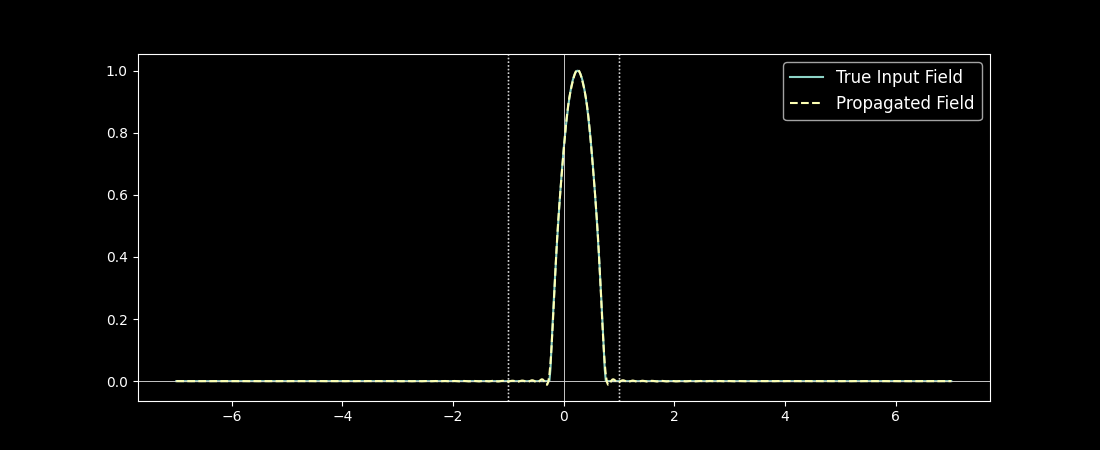

In [45]:
A.plot_field_1d(f0, label='True Input Field', figsize=(11,4.5));
A.add_1d_plot(P, ls='--', label='Propagated Field');

The full field appears as before:

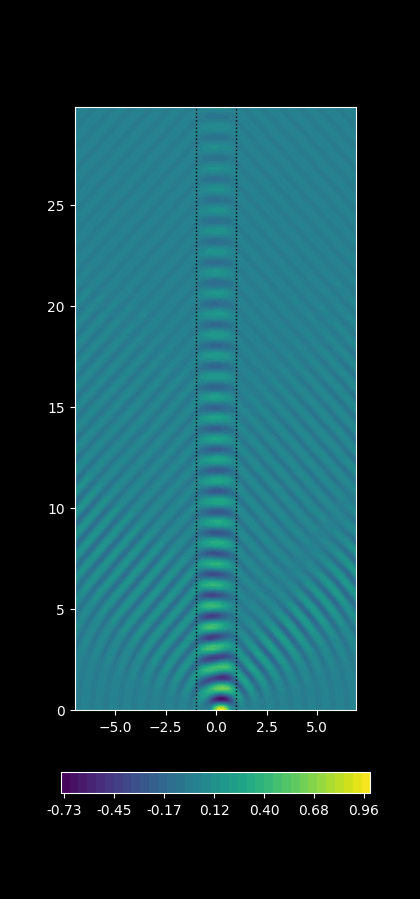

In [46]:
A.plot_field_2d(P, zmax=30, zref=200);

## Leaky Modes

To find these modes, we search in the complex plane:


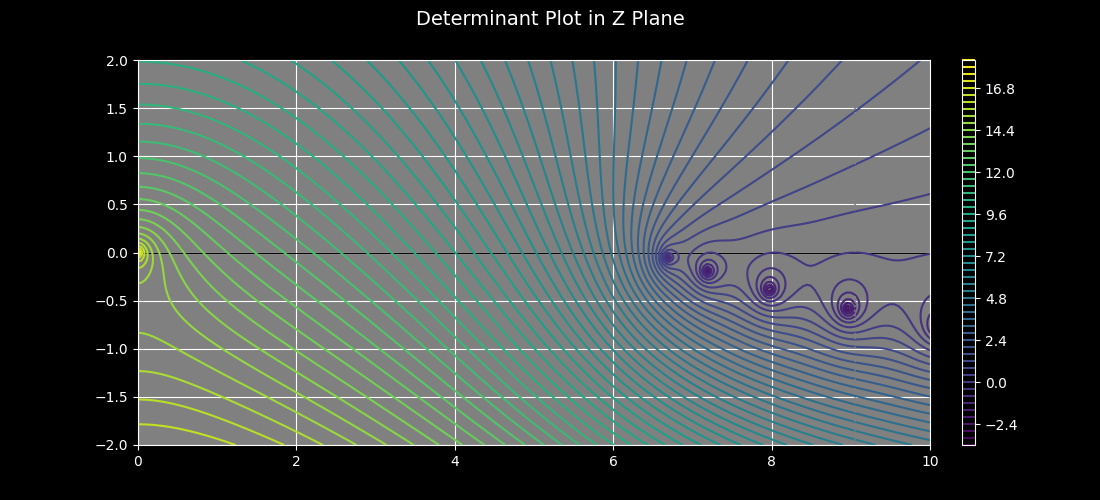

In [47]:
A.eigenvalue_plot(0, 10, -2, 2);

To get their propagation constants, we use the method get_leaky_propagation_constants.  This requires a window in which to search for their values, which we take from the plotting window:

In [48]:
A.get_leaky_propagation_constants(0, 10, -2, 2)

In [49]:
A.plot_points(A.leaky_prop_constants);

Next we find the modes:

In [50]:
A.get_leaky_modes();

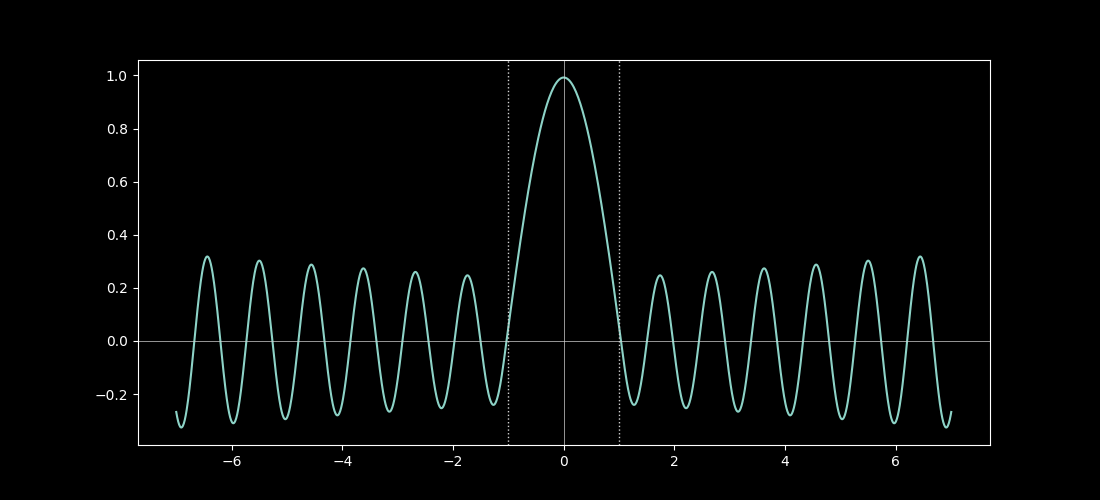

In [51]:
A.plot_field_1d(A.leaky_modes[0]);

Using the modes, we form the leaky field.  Note that this is done using the Propagator class defined earlier.

In [52]:
Leaky = P.get_leaky_field(indices=[0,1])

The keyword indices tells the Propagator to only use the leaky modes at those indices of the list Slab.leaky_modes when constructing the leaky field.  In this case, we only use the first two leaky modes, which correspond to those with the lowest loss and smallest real part.

The resulting leaky field is shown below:

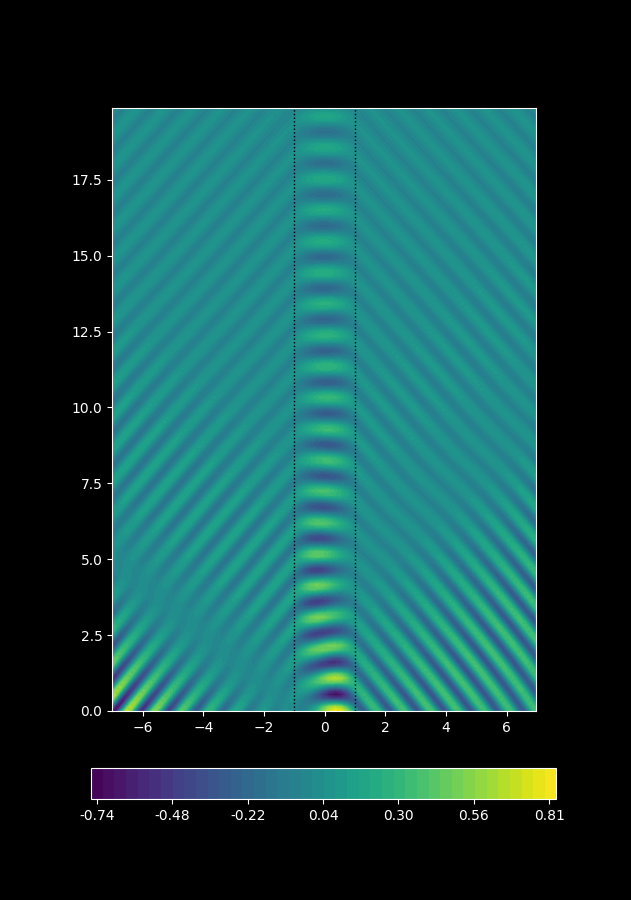

In [53]:
A.plot_field_2d(Leaky, zmax=20);

## Comparison of Leaky and True fields

Visually this leaky and true fields appear to be very similar, especially as we advance in the direction of propagation.  The plot below indicates that this is correct:

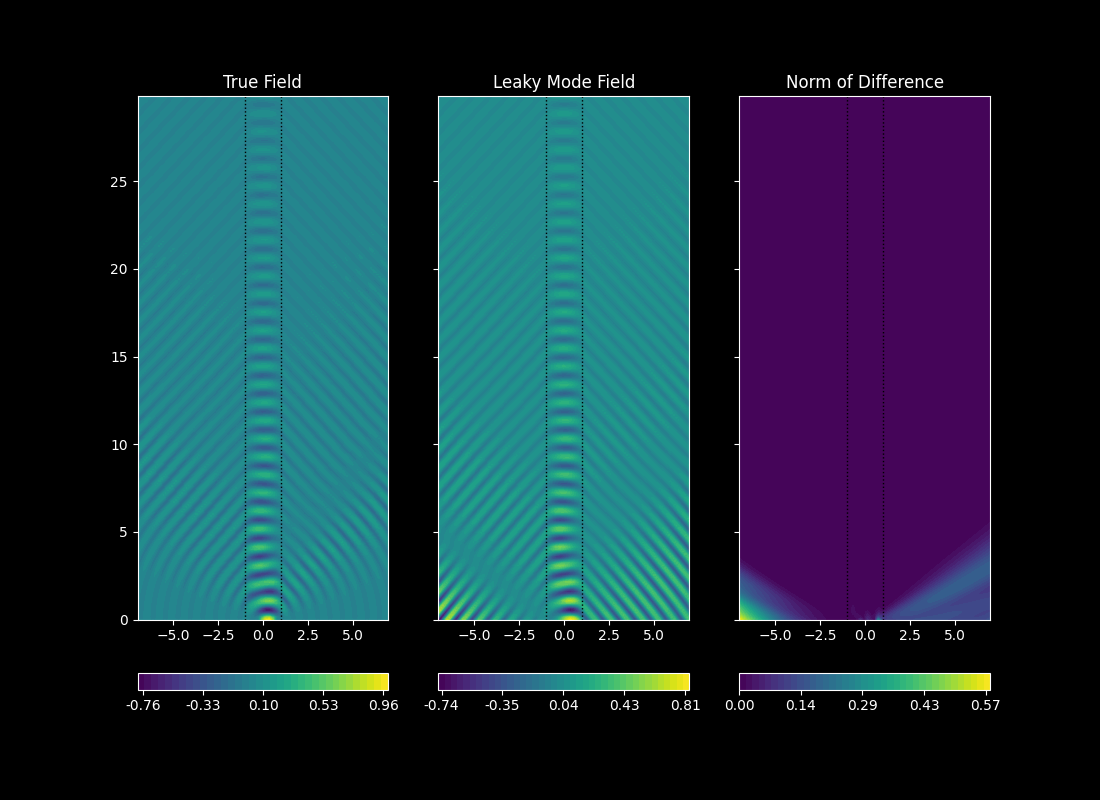

In [54]:
plt.close('all')
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True, figsize=(11,8))

zmin = 0
zmax = 30
zref = int((zmax-zmin)*15/2)
zs = np.linspace(zmin, zmax, zref)

A.add_2d_plot(P, ax=ax1, zs=zs, colorbar=True);
ax1.set_title('True Field')

A.add_2d_plot(Leaky, ax=ax2, zs=zs, colorbar=True);
ax2.set_title('Leaky Mode Field')

A.add_2d_plot(abs(P.Full-Leaky)**2, ax=ax3, zs=zs, part='norm', colorbar=True);
ax3.set_title('Norm of Difference');

We note that the fields nearly perfectly coincide for values of $z$ above 5, while for lower values they differ substantially, both in value and behavior.  This is expected for a leaky field, which only approximates the true field well in the direction of propagation.  Below, we observe this approximation in cross section:

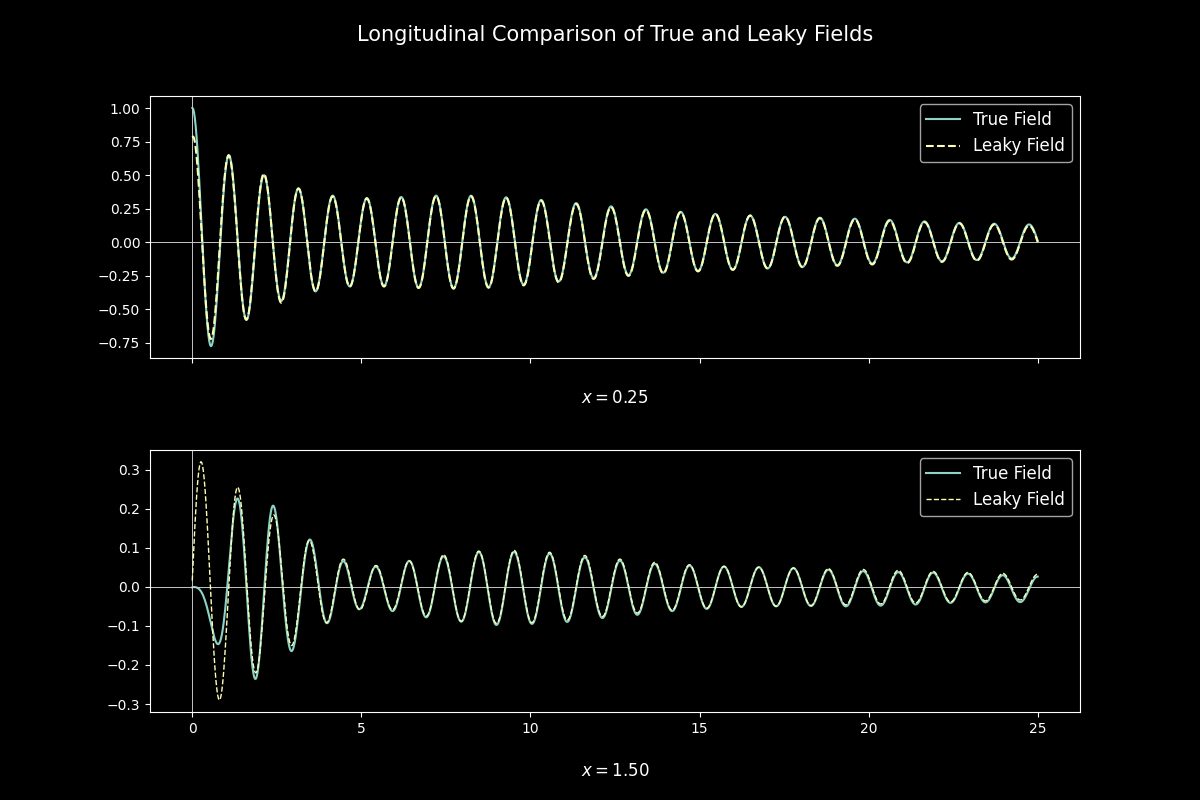

In [55]:
plt.close('all')
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(12,8), gridspec_kw = {'hspace':.35})

x1=shift
x2=1.5

zmin = 0
zmax = 25
zref = int((zmax-zmin)*80/2)
zs = np.linspace(zmin, zmax, zref)
ax1.set_title('Longitudinal Comparison of True and Leaky Fields\n\n', fontsize=15)

A.add_1d_plot(P, ax=ax1, xs=x1, zs=zs, label='True Field');
A.add_1d_plot(Leaky, ax=ax1, xs=x1, zs=zs, label='Leaky Field', ls='--');
# A.add_1d_plot(P.Full-Leaky, ax=ax1, xs=x1, zs=zs, label='Difference', lw=.75);
ax1.set_xlabel('\n$x=%.2f$'%x1, fontsize=12)


A.add_1d_plot(P, ax=ax2, xs=x2, zs=zs, label='True Field', lw=1.5);
A.add_1d_plot(Leaky, ax=ax2, xs=x2, zs=zs, label='Leaky Field', ls='--', lw=1);
# A.add_1d_plot(P.Full-Leaky, ax=ax2, xs=x2, zs=zs, label='Difference', lw=.75);
ax2.set_xlabel('\n$x=%.2f$'%x2, fontsize=12);

The plots above show longitudinal cross sections of the true and leaky fields at different values of transverse coordinate $x$.  We can see that the leaky field quickly begins to approximate the true field, though the transient portion differs at different values of $x$.

## Spike in radiation transform

With our understanding of leaky modes increasing, we are in a position to explain a phenomenon noted in 1.2.  There we saw that the radiation transform for the antiguide had a distinct spike:

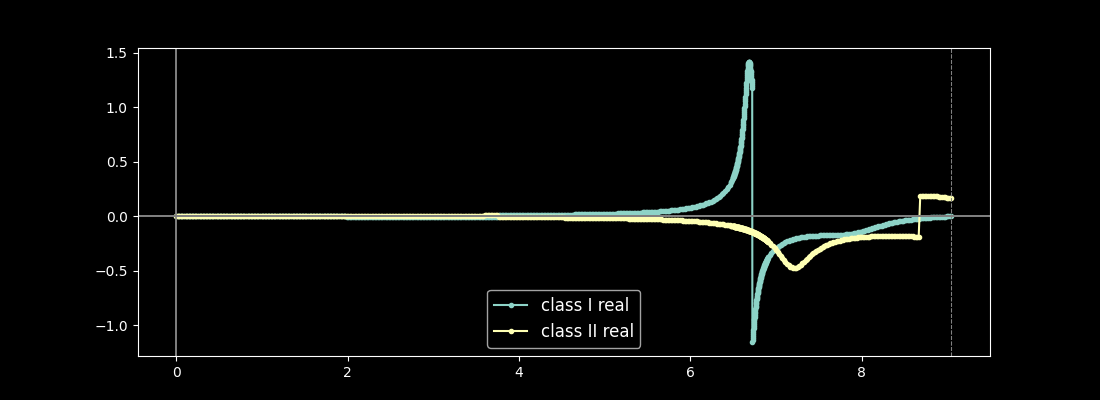

In [56]:
P.plot_transform(indices=slice(0,5), color_I='C0', color_II='C1');

We now note that this spike occurs very near the real part of the propagation constant of the lowest loss leaky mode:

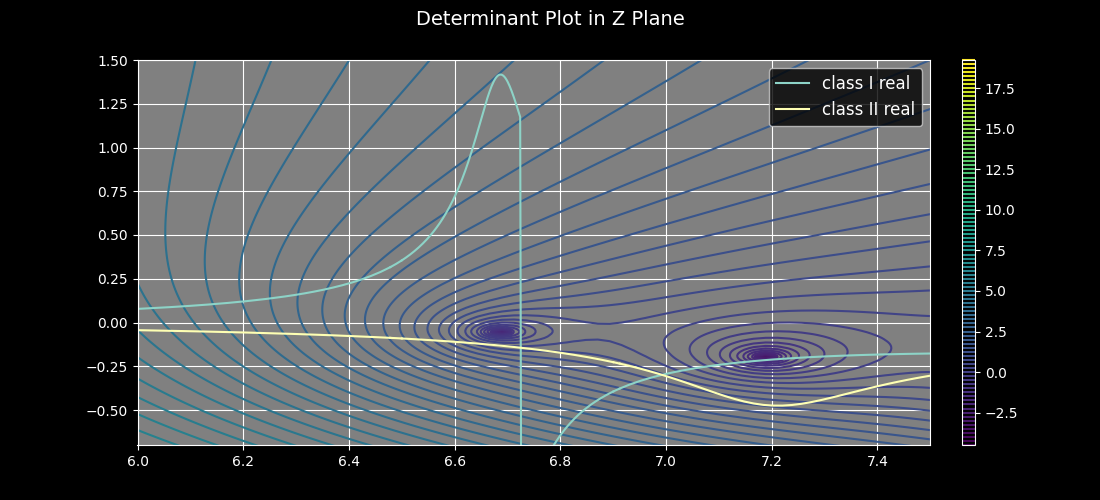

In [57]:
fig, ax,_ = A.eigenvalue_plot(0, A.Z_evanescent, -1,1.5, rref=400, iref=300, levels=100,
                             axis_linewidth=0);
P.plot_transform(ax=ax, indices=slice(0,5), color_I='C0', color_II='C1', marker=None, plot_axis=False);
ax.set_xlim(6,7.5);
ax.set_ylim(-.7,1.5);

Above we see a plot of the radiation transform overlaying a contour plot of the eigenvalue function.  Note that the primary spike in the transform occurs near to the real part of the propagation constant of the lowest loss leaky mode.  Also note the smaller spike near the next zero.  This begins to indicate a deeper connection between leaky modes and propagation that we will explore further in later examples.

### Transverse field at input

In [19]:
video_path = "animations/"

In [22]:
force_remake = False
file_path = video_path+"leaky.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_1d(A, Leaky, file_path='.mp4', linewidth=1.5, secs=2.5, fps=26, color='C0')

Video(file_path, html_attributes="controls loop")

### Full field

In [23]:
force_remake = False
file_path = video_path + "true_field_2d_animation.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_2d(A, P, file_path[:-4], zs=np.linspace(0, 12, 100), 
                    secs=2, fps=26, maxdim=6)

In [24]:
force_remake = False
file_path = video_path + "leaky_field_2d_animation.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_2d(A, P, file_path[:-4], zs=np.linspace(0, 12, 100), 
                    secs=2, fps=26, maxdim=6)

In [25]:
HTML("""
<video controls id="theVideo1"> <source src="animations/true_field_2d_animation.mp4"> </video>
<video controls id="theVideo2"> <source src="animations/leaky_field_2d_animation.mp4"> </video>
<script> video1 = document.getElementById("theVideo1")
video2 = document.getElementById("theVideo2")
video1.width = 500; video1.playbackRate = 1; video1.loop = true; video1.autoplay = true;
video2.width = 500; video2.playbackRate = 1; video2.loop = true; video2.autoplay = true;
</script> """)


### Animated surface plot

In [26]:
# Slow animation cell
force_remake = False
file_path = video_path + "true_field_3d_animation.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_2d_surface(A, P, file_path[:-4], fps=20, secs=2,
                               xs=np.linspace(-5,5,120), zmin=0, zmax=10, zref=200,
                               rstride=1, cstride=1, part='real',
                               azim=-47, elev=30, zoom=3.5, screen_dpi=120)

In [27]:
# Slow animation cell
force_remake = False
file_path = video_path + "leaky_field_3d_animation.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_2d_surface(A, Leaky, file_path[:-4], fps=20, secs=2,
                               xs=np.linspace(-6,6,120), zmin=0, zmax=10, zref=200,
                               rstride=1, cstride=1, part='real',
                               azim=-47, elev=30, zoom=3.5, screen_dpi=120)

In [28]:
HTML("""
<div style="text-align: center;">
<video controls id="theVideo3"> <source src="animations/true_field_3d_animation.mp4"> </video>
<video controls id="theVideo4"> <source src="animations/leaky_field_3d_animation.mp4"> </video>
<script> video3 = document.getElementById("theVideo3")
video4 = document.getElementById("theVideo4")
video3.width = 700; video3.playbackRate = 1; video3.loop = true; video3.autoplay = true;
video4.width = 700; video4.playbackRate = 1; video4.loop = true; video4.autoplay = true;
</script> 
</div>""")